# Essendon 2022 Voting Centres

District-wide results conceal differences between individual polling places. Let's take a look.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

In [3]:
from vecResults import getVotingCentres, CANDIDATES
results = getVotingCentres()
results.head()

,votingCentre,Animal Justice,Freedom,Greens,Socialists,Reason,Liberal,Labor,Family First,informal,totalVotes,voteType
0,Ascot Vale Central,38,27,259,88,44,382,687,19,57,1601,ordinary
1,Ascot Vale East,28,16,192,82,37,205,381,11,22,974,ordinary
2,Buckley Park,6,10,30,1,4,89,102,3,7,252,ordinary
3,Essendon,35,20,135,17,25,358,354,16,34,994,ordinary
4,Essendon North,26,23,118,29,20,340,386,26,47,1015,ordinary


## Preparing ordinary voting centre results

The VEC contains ordinary voting centres, other vote types, and summary rows. We will separate these.

Party shares use formal votes as the denominator.

In [ ]:
booths = results.loc[results["voteType"] == "ordinary"].copy()
booths["formalVotes"] = booths[CANDIDATES].sum(axis=1)

for party in CANDIDATES:
    booths[f"{party}Pct"] = 100 * booths[party] / booths["formalVotes"]

print(f"Ordinary voting centres: {len(booths)}")
print(f"Ordinary formal votes: {booths["formalVotes"].sum():,}")

booths[["votingCentre", "formalVotes", "LaborPct",
        "LiberalPct", "GreensPct"]].round(2)

Ordinary voting centres: 14
Ordinary formal votes: 13,593


,votingCentre,formalVotes,LaborPct,LiberalPct,GreensPct
0,Ascot Vale Central,1544,44.49,24.74,16.77
1,Ascot Vale East,952,40.02,21.53,20.17
2,Buckley Park,245,41.63,36.33,12.24
3,Essendon,960,36.88,37.29,14.06
4,Essendon North,968,39.88,35.12,12.19
5,Essendon West,557,40.39,42.55,8.26
6,Flemington,1289,39.64,12.26,27.70
7,Glenbervie,1397,39.58,30.99,14.03
8,Moonee Ponds,1102,37.84,35.12,17.60
9,Moonee Ponds Central,811,41.68,26.63,18.87


How does party support vary?

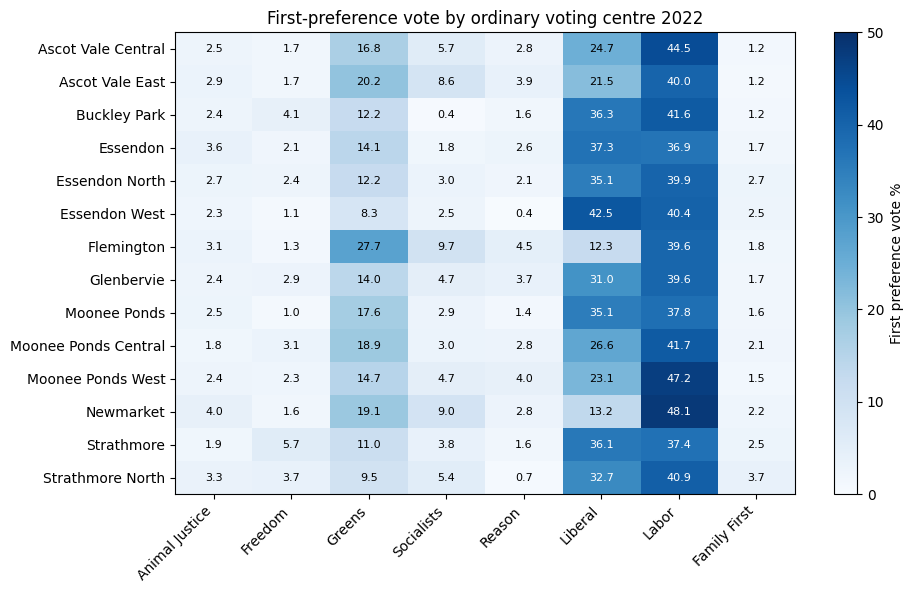

In [ ]:
partyShares = booths.set_index("votingCentre")[
    [f"{party}Pct" for party in CANDIDATES]]
partyShares.columns = CANDIDATES

fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(partyShares, aspect="auto", cmap="Blues", vmin=0, vmax=50)

ax.set_xticks(range(len(CANDIDATES)), CANDIDATES, rotation=45, ha="right")
ax.set_yticks(range(len(partyShares)), partyShares.index)
ax.set_title("First-preference vote by ordinary voting centre 2022")


for i in range(len(partyShares)):
    for j in range(len(CANDIDATES)):
        value = partyShares.iloc[i, j]
        ax.text(j, i, f"{value:.1f}", ha="center", va="center",
                fontsize=8, color="white" if value > 30 else "black")

fig.colorbar(image, ax=ax, label="First preference vote %")
plt.show()

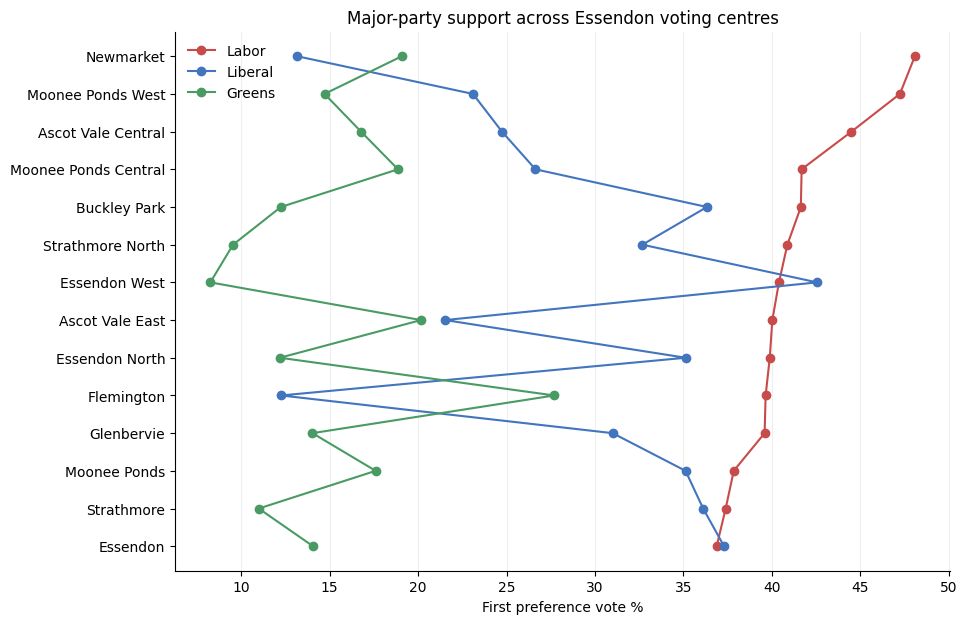

In [ ]:
major = ["Labor", "Liberal", "Greens"]
plotData = booths.sort_values("LaborPct").set_index("votingCentre")

fig, ax = plt.subplots(figsize=(10, 7))

for party, color in zip(major, ["#c84b4b", "#4275bd", "#499b63"]):
    ax.plot(plotData[f"{party}Pct"], plotData.index,
            "o-", label=party, color=color, linewidth=1.5)

ax.set_xlabel("First preference vote %")
ax.set_title("Major-party support across Essendon voting centres")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()